# FarmTech Solutions — Visão Computacional com YOLO
### Fase 6 · Cap 1 — O despertar da Rede Neural

**FIAP · Inteligência Artificial · 1TIAOA · 2026/1 — Grupo 51**

| Integrante | RM |
|---|---|
| Douglas Felicio da Silva | RM572312 |
| Gabriel Kaique Portel Silva | RM572500 |
| Richard Wrobel dos Santos | RM573998 |

Repositório: <https://github.com/DougFel/fiap-fase6-grupo51-farmtech-yolo>

---

**O pedido do cliente.** A FarmTech ampliou sua carteira para saúde animal e
segurança de propriedades rurais. Um cliente quer ver, na prática, como um
sistema de visão computacional reconhece objetos no campo — e com que confiança.

**O que este notebook entrega**

| Parte | Conteúdo | Seções |
|---|---|---|
| **Entrega 1** | YOLOv5 customizado para dois objetos (gado e maçã), treinado com **30** e **60** épocas, validado e testado | 1 a 5 |
| **Entrega 2** | Comparação com a **YOLO tradicional** (pré-treinada no COCO) e com uma **CNN treinada do zero** | 6 a 10 |
| Fechamento | Pontos fortes, limitações e próximos passos | 11 |

> **Como executar:** `Ambiente de execução → Alterar o tipo de ambiente → GPU (T4)`
> e depois `Executar tudo`. O notebook monta o **seu** Google Drive e, se a base
> ainda não estiver lá, copia as imagens e os rótulos do repositório para
> `MyDrive/FarmTech_Fase6/`. Tempo total com GPU T4: cerca de 15 minutos.

## 1. Cenário e escolha dos objetos

Escolhemos dois objetos **bem diferentes entre si**, como pede o enunciado, e
ambos ligados ao negócio da FarmTech:

| Classe | Objeto | Por que interessa ao cliente |
|---|---|---|
| `0 · gado` | gado bovino (vacas, bois, bezerros) | contagem de rebanho, saúde animal, cerca virtual |
| `1 · maca` | maçã | inspeção de pomar e de produção na esteira |

Os dois contrastam em quase tudo que importa para uma rede de detecção:
**escala** (um animal de 600 kg contra um fruto de 200 g), **forma** (silhueta
articulada contra contorno arredondado), **textura** (pelagem contra casca lisa) e
**cenário** (pasto e curral contra mesa, galho e estúdio).

**Origem das imagens.** As 80 fotos vêm do **Open Images V7** (Google), todas com
licença **Creative Commons BY 2.0**; autoria e link de cada uma estão em
`dataset/fontes.csv`. Partimos de um filtro automático (foto real, até 3 objetos,
objeto ocupando ao menos 4% da imagem) e depois fizemos **curadoria visual**: a
classe "Cattle" do Open Images mistura iaques, bisões e búfalos, e "Apple" inclui
tortas e fatias — ficamos só com gado bovino doméstico e maçãs inteiras.

**Rotulagem.** As caixas foram desenhadas no **Make Sense** (makesense.ai), uma
caixa por objeto, e exportadas em formato YOLO (um `.txt` por imagem). O pacote
original exportado está em `dataset/makesense/` e as caixas, em `dataset/labels/`.

![Rotulagem no Make Sense](https://raw.githubusercontent.com/DougFel/fiap-fase6-grupo51-farmtech-yolo/main/assets/makesense_rotulagem_gado.png)
*Projeto `farmtech-gado-maca` no Make Sense: as 80 imagens carregadas (✓ = rotulada) e duas
vacas marcadas com a classe `gado`.*

## 2. Ambiente: GPU, Google Drive e YOLOv5

A célula abaixo detecta se estamos no Colab, monta o Google Drive e define as
pastas do projeto. Fora do Colab (execução local), uma pasta `drive_local/` ao lado
do repositório faz o papel do Drive, para que o mesmo código rode nos dois lugares.

In [1]:
import os, sys, time, json, shutil, subprocess, random      # utilitários da biblioteca padrão
from pathlib import Path                                   # caminhos independentes de sistema operacional

EM_COLAB = 'google.colab' in sys.modules                   # True quando o notebook roda no Colab
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'                   # silencia avisos do TensorFlow (também nos subprocessos)

if EM_COLAB:
    from google.colab import drive                         # integração oficial do Colab com o Drive
    drive.mount('/content/drive')                          # pede autorização e monta o Drive do usuário
    RAIZ_DRIVE = Path('/content/drive/MyDrive')            # "Meu Drive"
    TRABALHO = Path('/content')                            # disco local da máquina do Colab (rápido)
else:
    RAIZ_DRIVE = Path.cwd().parent / 'drive_local'         # simula o Drive na execução local
    TRABALHO = Path.cwd().parent / '_trabalho'

PROJETO = RAIZ_DRIVE / 'FarmTech_Fase6'                    # pasta do projeto dentro do Drive
DATASET = PROJETO / 'dataset'                              # imagens + rótulos (treino, validação, teste)
RESULTADOS = PROJETO / 'resultados'                        # tudo que o notebook produz é salvo aqui
for pasta in (PROJETO, RESULTADOS, TRABALHO):
    pasta.mkdir(parents=True, exist_ok=True)

print('Executando no Colab' if EM_COLAB else 'Executando localmente')
print('Pasta do projeto:', PROJETO)

Mounted at /content/drive
Executando no Colab
Pasta do projeto: /content/drive/MyDrive/FarmTech_Fase6


In [2]:
import torch                                               # PyTorch: base do YOLOv5

GPU = torch.cuda.is_available()                            # há GPU CUDA disponível?
DISPOSITIVO = '0' if GPU else 'cpu'                        # formato esperado pelos scripts do YOLOv5
print('PyTorch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if GPU else 'não (CPU)')
if not GPU:
    print('Atenção: sem GPU o treino é ~100x mais lento. No Colab, ative a GPU T4.')

PyTorch 2.11.0+cu130 | GPU: Tesla T4


### 2.1 Base de imagens no Google Drive

Se a base ainda não estiver no Drive, ela é copiada do repositório do grupo. A
estrutura segue o padrão YOLO, com uma pasta por etapa:

```
MyDrive/FarmTech_Fase6/dataset/
├── images/  train/ (64)   val/ (8)   test/ (8)
├── labels/  train/ (64)   val/ (8)   test/ (8)    ← caixas do Make Sense (.txt)
├── makesense/  pacote exportado do Make Sense + lista de rótulos
└── fontes.csv  autoria e licença de cada imagem
```

In [3]:
REPO_URL = 'https://github.com/DougFel/fiap-fase6-grupo51-farmtech-yolo'                     # repositório público do grupo

if not (DATASET / 'images').exists():                      # base ausente no Drive → copiar do repositório
    if EM_COLAB:
        destino = TRABALHO / 'repo'
        if not destino.exists():
            subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(destino)], check=True)
        origem = destino / 'dataset'
    else:
        origem = Path.cwd().parent / 'dataset'             # local: a base já está no repositório
    shutil.copytree(origem, DATASET)                       # grava imagens e rótulos no Drive
    print('Base copiada para o Drive.')
else:
    print('Base já estava no Drive.')

# Conferência: quantas imagens e rótulos existem em cada etapa e de cada classe
for etapa in ('train', 'val', 'test'):
    imgs = sorted((DATASET / 'images' / etapa).glob('*.jpg'))
    rots = sorted((DATASET / 'labels' / etapa).glob('*.txt'))
    gado = sum(p.name.startswith('gado') for p in imgs)
    print(f'{etapa:>5}: {len(imgs):2d} imagens ({gado} gado, {len(imgs) - gado} maçã) | {len(rots):2d} arquivos de rótulo')

Base já estava no Drive.
train: 64 imagens (32 gado, 32 maçã) | 64 arquivos de rótulo
  val:  8 imagens (4 gado, 4 maçã) |  8 arquivos de rótulo
 test:  8 imagens (4 gado, 4 maçã) |  8 arquivos de rótulo


### 2.2 Conferência visual da rotulagem

Antes de treinar, desenhamos as caixas do Make Sense sobre algumas imagens de
treino. É a forma mais barata de pegar erro de rotulagem — o tipo de erro que um
modelo aprende e repete.

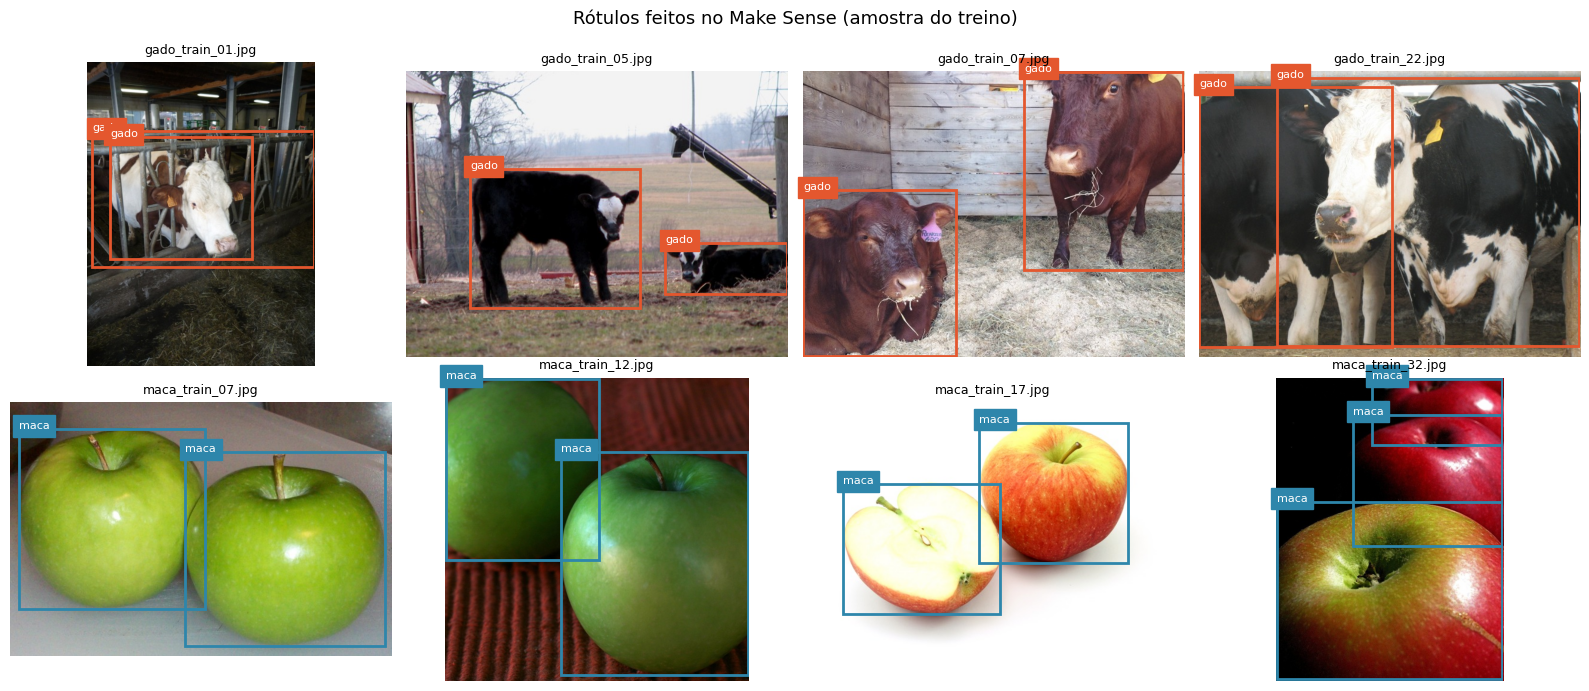

In [4]:
import numpy as np                                          # vetores e estatísticas
import pandas as pd                                         # tabelas
import io                                                   # buffer em memória para as figuras
import matplotlib.pyplot as plt                             # gráficos
import matplotlib.patches as patches                        # retângulos sobre as imagens
from PIL import Image                                       # leitura de imagens

from IPython.display import Image as ImagemPNG

def mostrar(fig, dpi=100):
    """Exibe a figura como PNG. Independe do backend: o YOLOv5 troca o do matplotlib para 'Agg' ao ser importado."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight')
    plt.close(fig)
    display(ImagemPNG(buf.getvalue()))

NOMES = {0: 'gado', 1: 'maca'}                              # mesma ordem dos rótulos no Make Sense
CORES = {0: '#e4572e', 1: '#2e86ab'}                        # uma cor por classe

def ler_rotulos(txt: Path):
    """Lê um arquivo YOLO: classe, centro x, centro y, largura, altura (normalizados 0-1)."""
    if not txt.exists():
        return []
    return [list(map(float, linha.split())) for linha in txt.read_text().splitlines() if linha.strip()]

def desenhar(ax, img_path: Path, rotulos, titulo=''):
    """Mostra a imagem com as caixas convertidas de YOLO (normalizado) para pixels."""
    img = Image.open(img_path); w, h = img.size
    ax.imshow(img); ax.set_axis_off(); ax.set_title(titulo, fontsize=9)
    for cls, xc, yc, bw, bh in rotulos:
        x0, y0 = (xc - bw / 2) * w, (yc - bh / 2) * h       # canto superior esquerdo
        ax.add_patch(patches.Rectangle((x0, y0), bw * w, bh * h, fill=False, lw=2, color=CORES[int(cls)]))
        ax.text(x0, y0, NOMES[int(cls)], color='white', fontsize=8, backgroundcolor=CORES[int(cls)])

amostra = [f'gado_train_{i:02d}.jpg' for i in (1, 5, 7, 22)] + [f'maca_train_{i:02d}.jpg' for i in (7, 12, 17, 32)]
fig, eixos = plt.subplots(2, 4, figsize=(16, 7))
for ax, nome in zip(eixos.ravel(), amostra):
    p = DATASET / 'images' / 'train' / nome
    desenhar(ax, p, ler_rotulos(DATASET / 'labels' / 'train' / p.with_suffix('.txt').name), nome)
plt.suptitle('Rótulos feitos no Make Sense (amostra do treino)', fontsize=13)
plt.tight_layout(); mostrar(fig)

In [5]:
# Estatísticas da base: objetos por imagem e tamanho das caixas (fração da área da imagem)
linhas = []
for etapa in ('train', 'val', 'test'):
    for txt in (DATASET / 'labels' / etapa).glob('*.txt'):
        for cls, xc, yc, bw, bh in ler_rotulos(txt):
            linhas.append({'etapa': etapa, 'classe': NOMES[int(cls)], 'imagem': txt.stem, 'area_relativa': bw * bh})
caixas = pd.DataFrame(linhas)

resumo = caixas.groupby(['etapa', 'classe']).agg(imagens=('imagem', 'nunique'), objetos=('imagem', 'size'),
                                                  area_media=('area_relativa', 'mean')).round(3)
display(resumo)
print(f"Total: {caixas.imagem.nunique()} imagens, {len(caixas)} objetos rotulados")

imagens  objetos  area_media
etapa classe                              
test  gado          4        8       0.486
      maca          4        4       0.595
train gado         32       40       0.493
      maca         32       40       0.387
val   gado          4        4       0.540
      maca          4        5       0.399

Total: 80 imagens, 101 objetos rotulados


**Leitura da base.** Cada imagem tem de 1 a 3 objetos, e os objetos são grandes
(em média ocupam mais da metade da foto). É um cenário favorável para o YOLO: com
só 32 imagens por classe, objetos pequenos ou muito sobrepostos seriam o primeiro
ponto de falha. Ao mesmo tempo, isso é uma **limitação** a declarar ao cliente —
voltamos a ela na seção 11.

### 2.3 YOLOv5

Usamos o repositório oficial da Ultralytics, **fixado num commit** para que o
resultado seja reprodutível mesmo que o repositório mude depois da entrega.

In [6]:
YOLO_DIR = TRABALHO / 'yolov5'
COMMIT = 'f9578796b8a64889aa9e66dc06914d19f40d338e'                         # versão do YOLOv5 usada no projeto

if not YOLO_DIR.exists():
    subprocess.run(['git', 'clone', 'https://github.com/ultralytics/yolov5', str(YOLO_DIR)], check=True)
    subprocess.run(['git', '-C', str(YOLO_DIR), 'checkout', '-q', COMMIT], check=True)
if EM_COLAB:                                                # no Colab, instala as dependências do YOLOv5
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(YOLO_DIR / 'requirements.txt')], check=True)
sys.path.insert(0, str(YOLO_DIR))                           # permite importar val.py e os utilitários
from utils.downloads import attempt_download                # utilitário do próprio YOLOv5
attempt_download(YOLO_DIR / 'yolov5s.pt')                   # baixa os pesos COCO agora: o download não entra no tempo de treino
print('YOLOv5 em', YOLO_DIR, '| commit', subprocess.run(['git', '-C', str(YOLO_DIR), 'rev-parse', '--short', 'HEAD'],
      capture_output=True, text=True).stdout.strip())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


100%|██████████| 14.1M/14.1M [00:00<00:00, 97.6MB/s]


YOLOv5 em /content/yolov5 | commit f9578796


In [7]:
# Arquivo de configuração da base: onde estão as imagens e quais são as classes
DATA_YAML = PROJETO / 'farmtech.yaml'
DATA_YAML.write_text(f"""path: {DATASET}
train: images/train
val: images/val
test: images/test
names:
  0: gado
  1: maca
""")
print(DATA_YAML.read_text())

IMG = 640                                                  # tamanho de entrada da rede (pixels)

path: /content/drive/MyDrive/FarmTech_Fase6/dataset
train: images/train
val: images/val
test: images/test
names:
  0: gado
  1: maca



## 3. Treinamento — duas simulações: 30 e 60 épocas

Partimos dos pesos **`yolov5s.pt`** (pré-treinados no COCO) e ajustamos a rede às
nossas duas classes — o caminho recomendado no capítulo 3 para bases pequenas.
As duas simulações são **idênticas em tudo, menos no número de épocas**, para que
a diferença de resultado possa ser atribuída só a esse parâmetro:

| Parâmetro | Valor | Motivo |
|---|---|---|
| Modelo base | YOLOv5s (7 M parâmetros) | leve, treina rápido na T4 e roda em tempo real |
| Imagem | 640 px | tamanho nativo do YOLOv5 |
| Lote (batch) | 16 | cabe na memória da T4 com folga |
| Semente | 0 (padrão do YOLOv5) | mesma inicialização nas duas simulações |
| Épocas | **30** e **60** | bem diferentes, como pede o enunciado |

O treino usa a pasta `train` e, ao fim de cada época, avalia na pasta `val`
(validação). O melhor peso (`best.pt`) é escolhido pela métrica de validação.

In [8]:
def rodar(cmd, cwd=YOLO_DIR, linhas_finais=12):
    """Executa um script do YOLOv5, mostra o fim da saída e devolve o tempo gasto (s)."""
    inicio = time.time()
    proc = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    ruido = ('absl', 'cudart_stub', 'cuda drivers', 'B/s]', 'it/s]', 'Downloading')  # avisos e barras de download
    saida = [l for l in (proc.stdout + proc.stderr).splitlines() if l.strip() and not any(r in l for r in ruido)]
    print('\n'.join(saida[-linhas_finais:]))
    if proc.returncode != 0:
        raise RuntimeError('falhou: ' + ' '.join(map(str, cmd)))
    return time.time() - inicio

EXPERIMENTOS = {'30 épocas': 30, '60 épocas': 60}  # nome do experimento → épocas
tempos_treino = {}

for nome, epocas in EXPERIMENTOS.items():
    print(f'===== Treinando: {nome} =====')
    tempos_treino[nome] = rodar([
        sys.executable, 'train.py',
        '--img', str(IMG), '--batch', '16', '--epochs', str(epocas),
        '--data', str(DATA_YAML), '--weights', 'yolov5s.pt',
        '--project', str(YOLO_DIR / 'runs' / 'train'), '--name', f'farmtech_{epocas}ep', '--exist-ok',
        '--cache', 'ram', '--device', DISPOSITIVO,
    ])
    print(f'Tempo de treino ({nome}): {tempos_treino[nome] / 60:.1f} min\n')

PESOS = {nome: YOLO_DIR / 'runs' / 'train' / f'farmtech_{ep}ep' / 'weights' / 'best.pt' for nome, ep in EXPERIMENTOS.items()}

===== Treinando: 30 épocas =====
                   all          8          9      0.897      0.993       0.92      0.742
30 epochs completed in 0.016 hours.
Optimizer stripped from /content/yolov5/runs/train/farmtech_30ep/weights/last.pt, 14.4MB
Optimizer stripped from /content/yolov5/runs/train/farmtech_30ep/weights/best.pt, 14.4MB
Validating /content/yolov5/runs/train/farmtech_30ep/weights/best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 8.7it/s 0.1s
                   all          8          9      0.897      0.992       0.92      0.742
                  gado          8          4      0.794          1      0.845      0.629
                  maca          8          5          1      0.984      0.995      0.855
Results saved to /content/yolov5/runs/train/farmtech_30ep
Tempo de treino (30 épocas): 2.6 min

===== Treinand

### 3.1 Curvas de treino: erro e acerto por época

O `results.csv` de cada treino registra, época a época, as **perdas** (o "erro"
que a rede minimiza) e as métricas na validação. As três perdas do YOLO medem
coisas diferentes:

- **box** — quão longe a caixa prevista está da caixa verdadeira;
- **obj** — se a rede acerta *onde há objeto* (objectness);
- **cls** — se acerta *qual* objeto é (gado ou maçã).

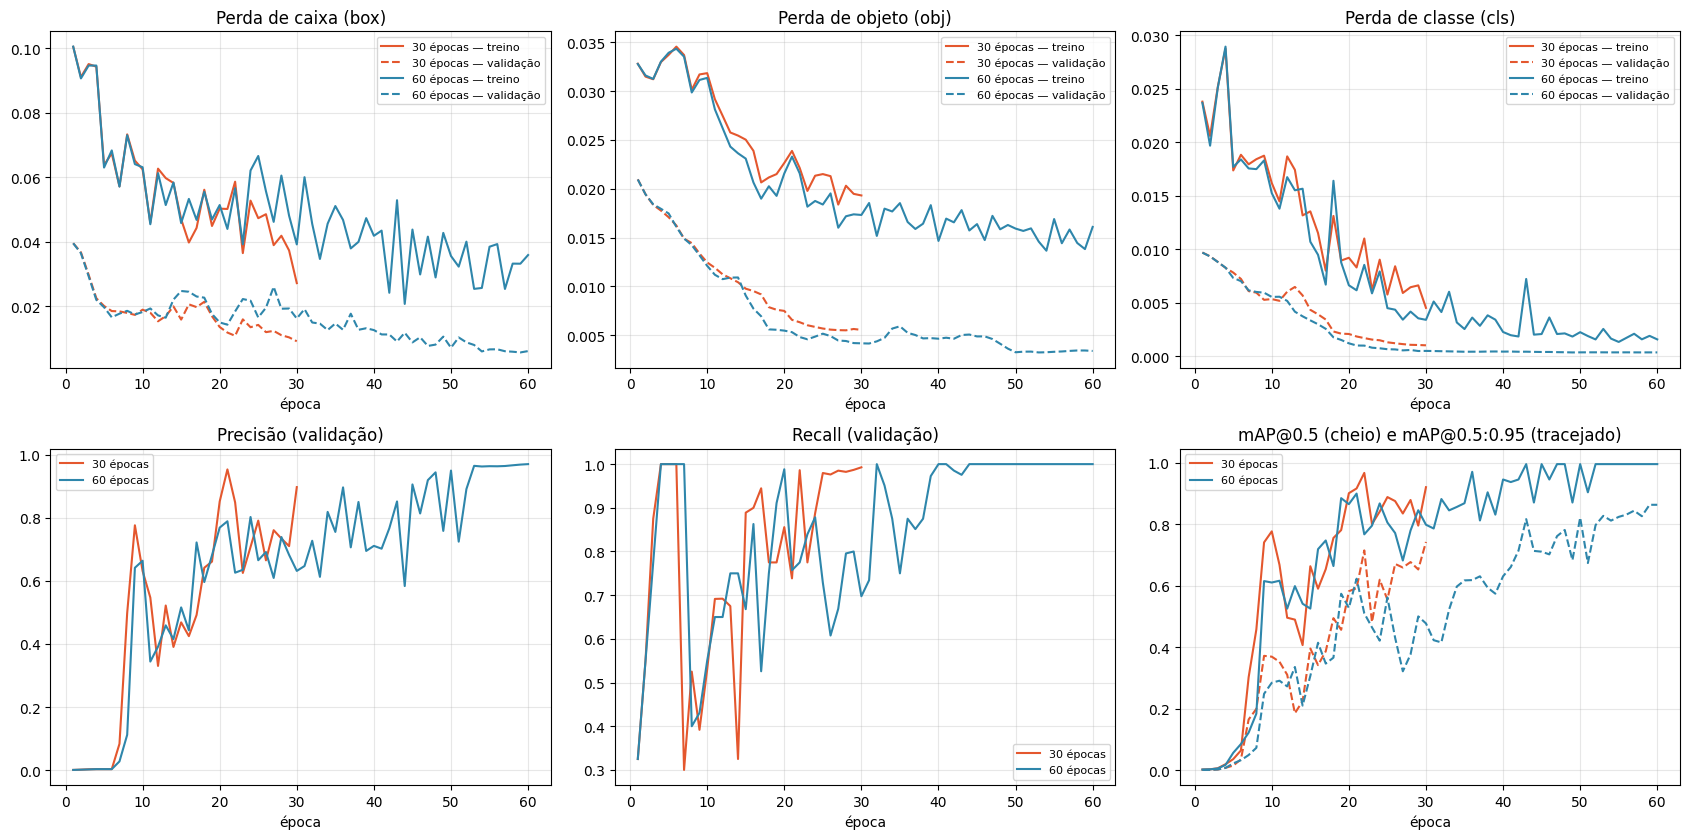

In [9]:
def historico(nome):
    """Lê o results.csv de um treino (o YOLOv5 grava os nomes das colunas com espaços)."""
    df = pd.read_csv(PESOS[nome].parents[1] / 'results.csv')
    df.columns = [col.strip() for col in df.columns]
    return df

hist = {nome: historico(nome) for nome in EXPERIMENTOS}

graficos = [('train/box_loss', 'val/box_loss', 'Perda de caixa (box)'),
            ('train/obj_loss', 'val/obj_loss', 'Perda de objeto (obj)'),
            ('train/cls_loss', 'val/cls_loss', 'Perda de classe (cls)'),
            ('metrics/precision', None, 'Precisão (validação)'),
            ('metrics/recall', None, 'Recall (validação)'),
            ('metrics/mAP_0.5', 'metrics/mAP_0.5:0.95', 'mAP@0.5 (cheio) e mAP@0.5:0.95 (tracejado)')]
fig, eixos = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col1, col2, titulo) in zip(eixos.ravel(), graficos):
    for nome, cor in zip(EXPERIMENTOS, ('#e4572e', '#2e86ab')):
        df = hist[nome]
        ax.plot(df.epoch + 1, df[col1], color=cor, label=f'{nome}' + (' — treino' if 'loss' in col1 else ''))
        if col2:
            ax.plot(df.epoch + 1, df[col2], color=cor, ls='--', label=f'{nome} — validação' if 'loss' in col2 else None)
    ax.set_title(titulo); ax.set_xlabel('época'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTADOS / 'curvas_treino.png', dpi=120); mostrar(fig)

**Como ler as curvas.** As linhas cheias de perda caindo mostram que a rede está
aprendendo; as tracejadas (validação) mostram se esse aprendizado vale para
imagens que ela não viu. Se a perda de treino continuasse caindo enquanto a de
validação subisse, seria o sinal clássico de *overfitting*. A comparação das
duas simulações está na seção 5, depois da avaliação no teste.

## 4. Validação e teste

Avaliamos o `best.pt` de cada simulação em duas bases que **não participaram do
ajuste dos pesos**:

- **validação** (8 imagens) — usada pelo YOLO para escolher o melhor peso;
- **teste** (8 imagens) — nunca vista em nenhuma decisão de treino; é a medida
  honesta de como o modelo se comportaria no cliente.

Métricas: **precisão** (das detecções feitas, quantas estão certas), **recall**
(dos objetos reais, quantos foram achados), **mAP@0.5** (precisão média com caixa
aceita se IoU ≥ 0,5) e **mAP@0.5:0.95** (média em IoU de 0,5 a 0,95, mais exigente).

In [10]:
import val as yolo_val                                      # módulo de avaliação do próprio YOLOv5

def avaliar(nome, etapa):
    """Roda o val.py do YOLOv5 e devolve as métricas gerais e o tempo de inferência."""
    (p, r, map50, map5095, *_), _, tempos = yolo_val.run(
        data=str(DATA_YAML), weights=str(PESOS[nome]), task=etapa, imgsz=IMG, batch_size=8,
        device=DISPOSITIVO, project=str(YOLO_DIR / 'runs' / 'val'), name=f"{nome.split()[0]}ep_{etapa}",
        exist_ok=True, verbose=True, plots=True)
    return {'simulação': nome, 'base': etapa, 'precisão': p, 'recall': r, 'mAP@0.5': map50,
            'mAP@0.5:0.95': map5095, 'inferência (ms/img)': tempos[1]}

avaliar(next(iter(EXPERIMENTOS)), 'val')                  # aquecimento da GPU: a 1ª chamada carrega kernels CUDA e distorce o tempo
metricas = pd.DataFrame([avaliar(nome, etapa) for nome in EXPERIMENTOS for etapa in ('val', 'test')])
display(metricas.round(3))

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/drive/MyDrive/FarmTech_Fase6/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.8s/it 1.8s
                   all          8          9      0.897      0.992       0.92      0.742
                  gado          8          4      0.794          1      0.845      0.629
                  maca          8          5          1      0.984      0.995      0.855
Speed: 1.4ms pre-process, 98.4ms inference, 28.2ms NMS per image at shape (8, 3, 640, 640)
Results saved to /content/yolov5/runs/val/30ep_val
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients,

,simulação,base,precisão,recall,mAP@0.5,mAP@0.5:0.95,inferência (ms/img)
0,30 épocas,val,0.897,0.992,0.920,0.742,5.496
1,30 épocas,test,0.611,0.827,0.739,0.439,5.246
2,60 épocas,val,0.970,1.000,0.995,0.863,7.392
3,60 épocas,test,0.789,0.750,0.811,0.569,5.447


### 4.1 Prints do teste — o que o cliente vai ver

O `detect.py` processa as 8 imagens de teste e grava as imagens com as caixas e a
confiança de cada detecção. A saída fica em `yolov5/runs/detect/expX`, onde X
aumenta a cada execução — aqui, `exp` para 30 épocas e `exp2` para 60.

In [11]:
pastas_detect = {}
for nome in EXPERIMENTOS:
    antes = set((YOLO_DIR / 'runs' / 'detect').glob('exp*'))
    rodar([sys.executable, 'detect.py', '--weights', str(PESOS[nome]), '--source', str(DATASET / 'images' / 'test'),
           '--img', str(IMG), '--conf-thres', '0.25', '--device', DISPOSITIVO], linhas_finais=3)
    nova = sorted(set((YOLO_DIR / 'runs' / 'detect').glob('exp*')) - antes, key=lambda p: p.stat().st_mtime)[-1]
    pastas_detect[nome] = nova                              # guarda qual expX pertence a qual simulação
    print(f'{nome}: resultados em {nova.relative_to(TRABALHO)}\n')

image 8/8 /content/drive/MyDrive/FarmTech_Fase6/dataset/images/test/maca_test_04.jpg: 640x480 3 macas, 12.9ms
Speed: 0.5ms pre-process, 23.6ms inference, 16.1ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/exp
30 épocas: resultados em yolov5/runs/detect/exp

image 8/8 /content/drive/MyDrive/FarmTech_Fase6/dataset/images/test/maca_test_04.jpg: 640x480 4 macas, 9.6ms
Speed: 0.5ms pre-process, 21.7ms inference, 14.9ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/exp2
60 épocas: resultados em yolov5/runs/detect/exp2



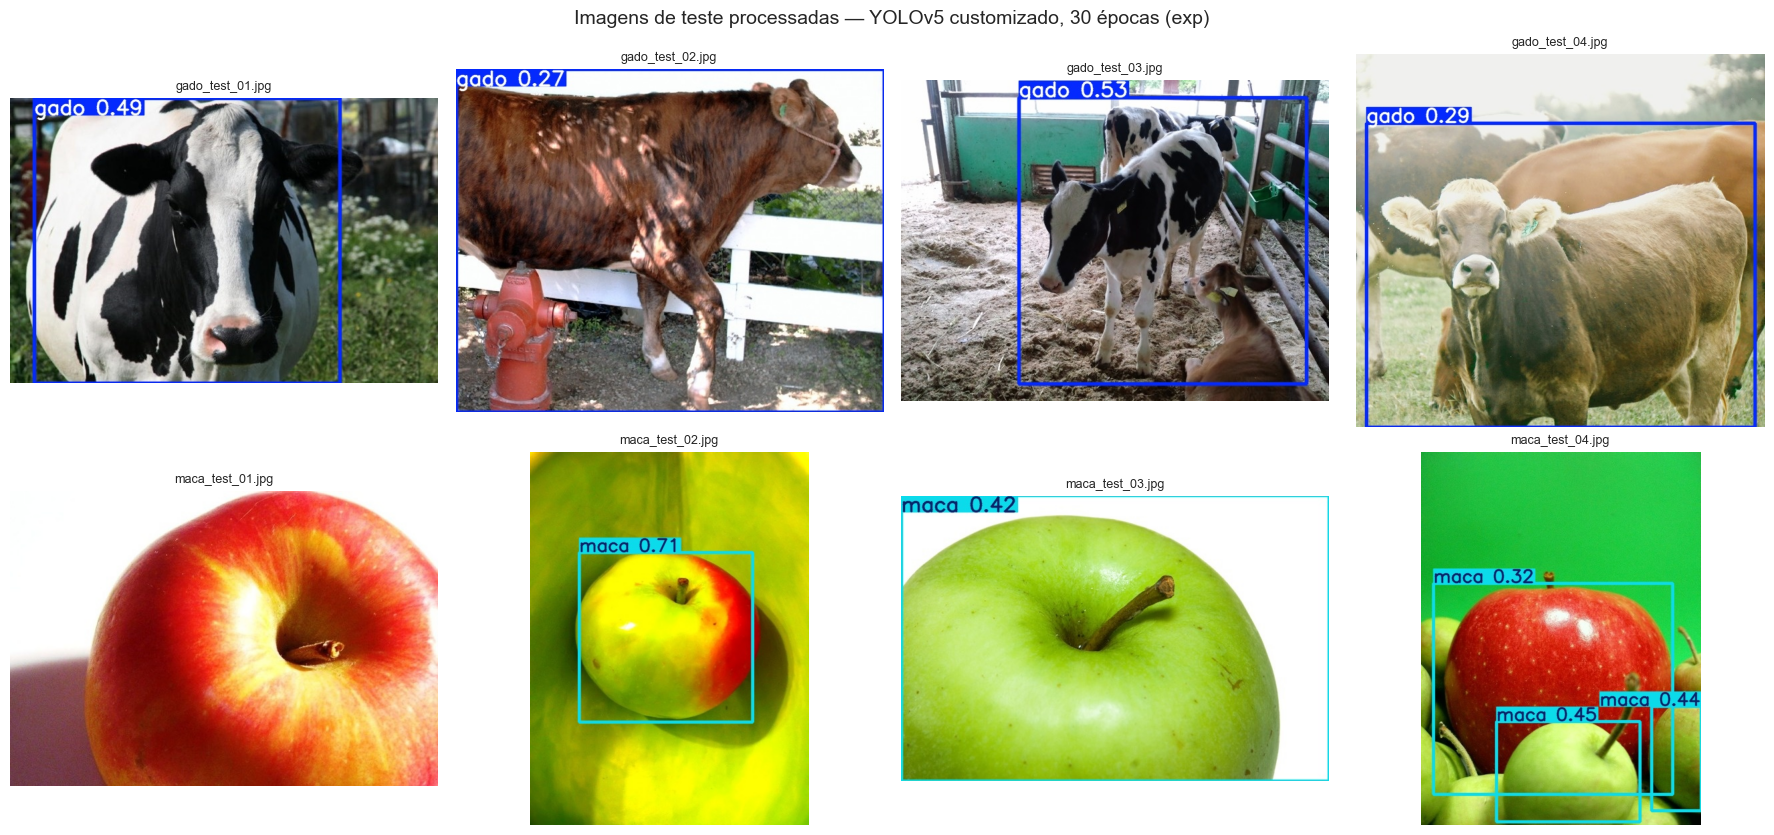

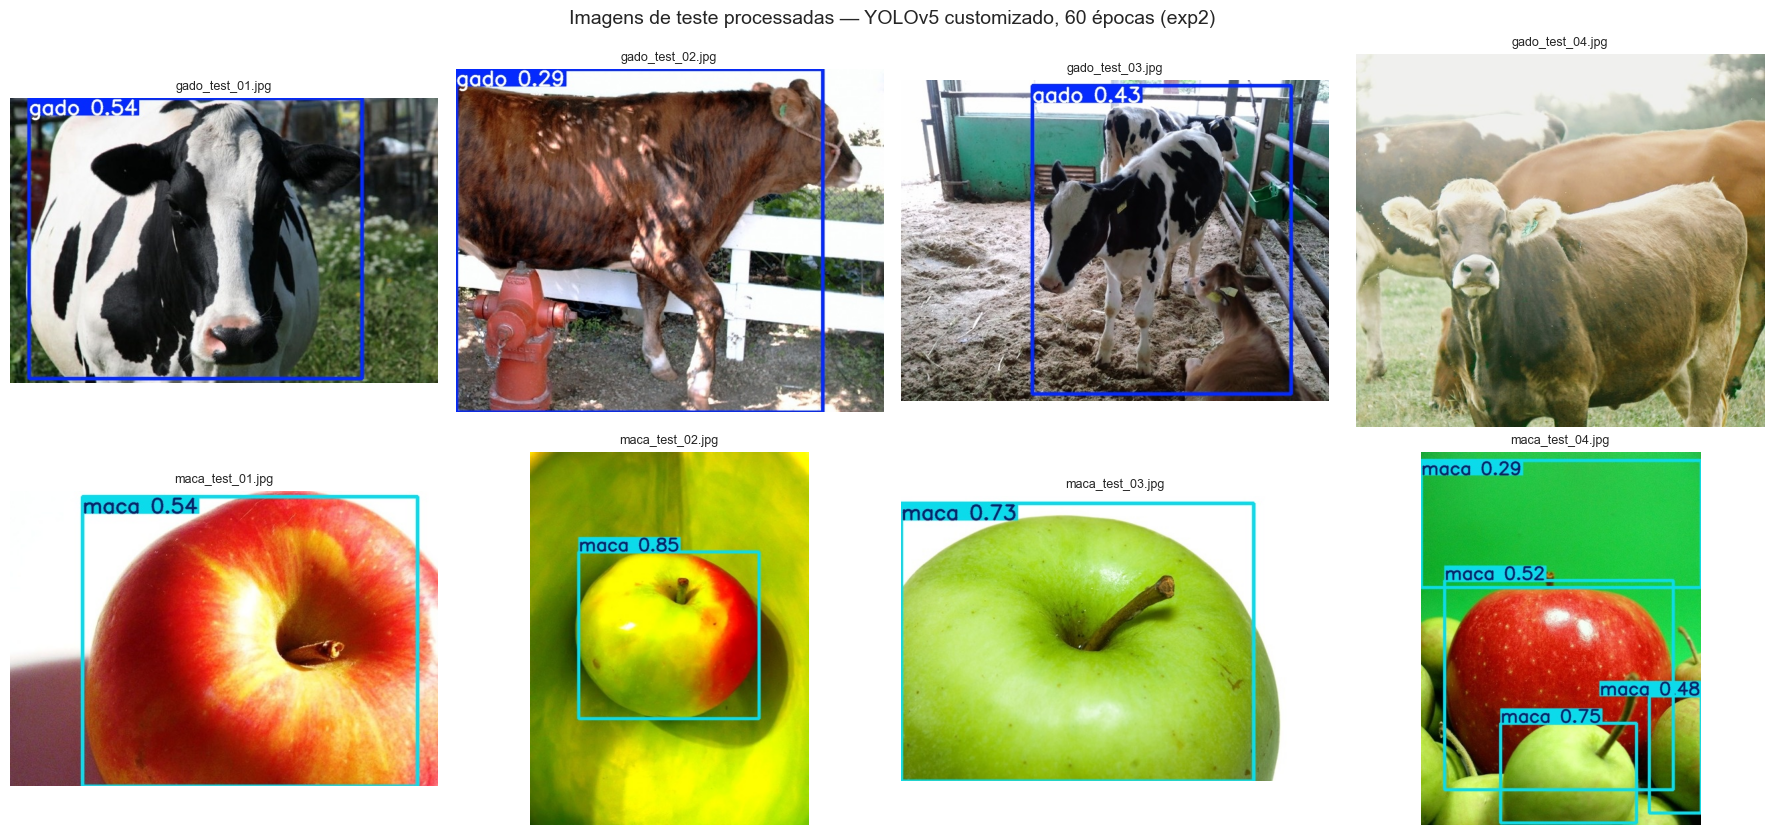

In [12]:
def galeria(pasta, titulo):
    """Mostra as 8 imagens de teste processadas pelo modelo."""
    imagens = sorted(pasta.glob('*.jpg'))
    fig, eixos = plt.subplots(2, 4, figsize=(18, 8.5))
    for ax, p in zip(eixos.ravel(), imagens):
        ax.imshow(Image.open(p)); ax.set_axis_off(); ax.set_title(p.name, fontsize=9)
    plt.suptitle(titulo, fontsize=14); plt.tight_layout()
    plt.savefig(RESULTADOS / f'teste_{pasta.name}.jpg', dpi=110); mostrar(fig)

for nome, pasta in pastas_detect.items():
    galeria(pasta, f'Imagens de teste processadas — YOLOv5 customizado, {nome} ({pasta.name})')

## 5. 30 x 60 épocas: acurácia, erro e desempenho

Juntamos numa tabela o que o enunciado pede para comparar: **acurácia** (precisão,
recall, mAP), **erro** (perdas finais de treino e validação) e **desempenho**
(tempo de treino e de inferência).

In [13]:
linhas = []
for nome in EXPERIMENTOS:
    fim = hist[nome].iloc[-1]                                # última época de cada treino
    teste = metricas[(metricas['simulação'] == nome) & (metricas.base == 'test')].iloc[0]
    validacao = metricas[(metricas['simulação'] == nome) & (metricas.base == 'val')].iloc[0]
    linhas.append({
        'simulação': nome,
        'mAP@0.5 val': validacao['mAP@0.5'], 'mAP@0.5 teste': teste['mAP@0.5'],
        'mAP@0.5:0.95 teste': teste['mAP@0.5:0.95'],
        'precisão teste': teste['precisão'], 'recall teste': teste['recall'],
        'perda total treino': fim['train/box_loss'] + fim['train/obj_loss'] + fim['train/cls_loss'],
        'perda total val': fim['val/box_loss'] + fim['val/obj_loss'] + fim['val/cls_loss'],
        'tempo de treino (min)': tempos_treino[nome] / 60,
        'inferência (ms/img)': teste['inferência (ms/img)'],
    })
comparacao_epocas = pd.DataFrame(linhas).set_index('simulação')
display(comparacao_epocas.round(3).T)
comparacao_epocas.to_csv(RESULTADOS / 'comparacao_30x60.csv')

simulação,30 épocas,60 épocas
mAP@0.5 val,0.920,0.995
mAP@0.5 teste,0.739,0.811
mAP@0.5:0.95 teste,0.439,0.569
precisão teste,0.611,0.789
recall teste,0.827,0.750
perda total treino,0.051,0.054
perda total val,0.016,0.010
tempo de treino (min),2.589,2.166
inferência (ms/img),5.246,5.447


### Conclusões da Entrega 1


**1. Mais épocas ajudaram — e a rede ainda estava aprendendo aos 30.** Com 60
épocas o modelo foi melhor em todas as medidas que importam no teste:

| Teste (8 imagens, 12 objetos) | 30 épocas | 60 épocas |
|---|---|---|
| mAP@0.5 | 0,739 | **0,811** |
| mAP@0.5:0.95 (caixa precisa) | 0,439 | **0,569** |
| Precisão | 0,611 | **0,789** |
| Recall | **0,827** | 0,750 |

O ganho maior está no **mAP@0.5:0.95**, que exige caixas bem ajustadas: as
épocas extras refinaram a *localização*, não só o reconhecimento. As curvas da
seção 3.1 mostram que a perda de validação continuou caindo até a época 60 —
**não houve overfitting**, então 30 épocas interrompem um aprendizado ainda em curso.

**2. Erro.** A perda total de validação caiu de 0,016 (30 épocas) para 0,010
(60 épocas). A de treino fica em torno de 0,05 nos dois casos porque é medida com
aumento de dados (mosaico, cortes, variação de cor); por isso ela é *maior* que a
de validação, e isso não indica problema.

**3. Desempenho.** A inferência é a mesma nos dois modelos (~5 ms por imagem na
T4) — a arquitetura é idêntica, só os pesos mudam. Os tempos de treino ficaram
próximos (2,6 e 2,2 min): o primeiro treino paga custos únicos de preparação
(cache das imagens lidas do Drive, verificações iniciais), por isso o de 30 épocas
não saiu na metade do de 60. Por época, o custo real é de ~2 s.

**4. Validação × teste.** Na validação os dois modelos ficam perto do teto
(mAP@0.5 de 0,920 e 0,995), mas no teste caem para 0,74 e 0,81. A diferença não é
"defeito" do modelo e sim do tamanho das bases: a validação tem 8 imagens com
quase um objeto cada, enquanto o teste tem **duas fotos de rebanho com 3 animais**.
Os prints da seção 4.1 mostram exatamente onde o modelo erra:

- **acerta** todas as fotos com um animal e todas as maçãs;
- em `gado_test_03` agrupa os animais numa caixa só, e em `gado_test_04` (rebanho
  em fundo enevoado) **não detecta nada** — por isso o recall do gado no teste é
  0,50 enquanto o da maçã é 1,00;
- em `maca_test_04` encontra também maçãs cortadas na borda, que não foram
  rotuladas — viram falsos positivos, e é isso que puxa a precisão da maçã para baixo.

**5. Variação entre execuções.** Com 8 imagens de teste, um único objeto muda o
mAP em vários pontos, e o treino em GPU não é perfeitamente determinístico. Numa
execução anterior idêntica, o modelo de 60 épocas chegou a 0,848 de mAP@0.5 no
teste. A conclusão — **60 épocas superam 30** — se repetiu em todas as execuções;
os valores exatos devem ser lidos com essa margem.

**Mensagem para o cliente.** Com 32 fotos por classe e 2 minutos de GPU, o
detector já reconhece gado e maçã com confiança em cenas com um ou poucos
objetos. Para contar animais num rebanho, o próximo passo é treinar com mais
fotos de grupo — é a única situação em que ele falha de forma sistemática.

---
# 6. Entrega 2 — A YOLO customizada contra as alternativas

Avaliamos três abordagens sobre **a mesma base de teste** (as 8 imagens que
nenhum modelo usou para aprender):

| # | Abordagem | O que faz | Treino nosso |
|---|---|---|---|
| A | **YOLOv5 customizado** (Entrega 1) | detecta e classifica gado e maçã | sim (ajuste fino) |
| B | **YOLO tradicional** | YOLOv5s com os pesos originais do COCO, sem nenhum ajuste | não |
| C | **CNN treinada do zero** | classifica a imagem inteira em gado ou maçã | sim (do zero) |

Para comparar detectores e classificador de forma justa, usamos duas medidas:

1. **mAP@0.5 de detecção** — só para A e B, que localizam objetos;
2. **acurácia de classificação da imagem** — para as três: nos detectores, a
   classe da imagem é a da detecção mais confiante.

## 7. YOLO tradicional (COCO, sem customização)

O COCO tem 80 classes, entre elas **`cow`** (19) e **`apple`** (47). Rodamos o
YOLOv5s original só com essas duas classes e mapeamos `cow → gado` e
`apple → maca`. Assim medimos o que o cliente teria **sem treinar nada**.

image 8/8 /content/drive/MyDrive/FarmTech_Fase6/dataset/images/test/maca_test_04.jpg: 640x480 7 apples, 13.5ms
Speed: 0.6ms pre-process, 32.5ms inference, 27.4ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/exp3


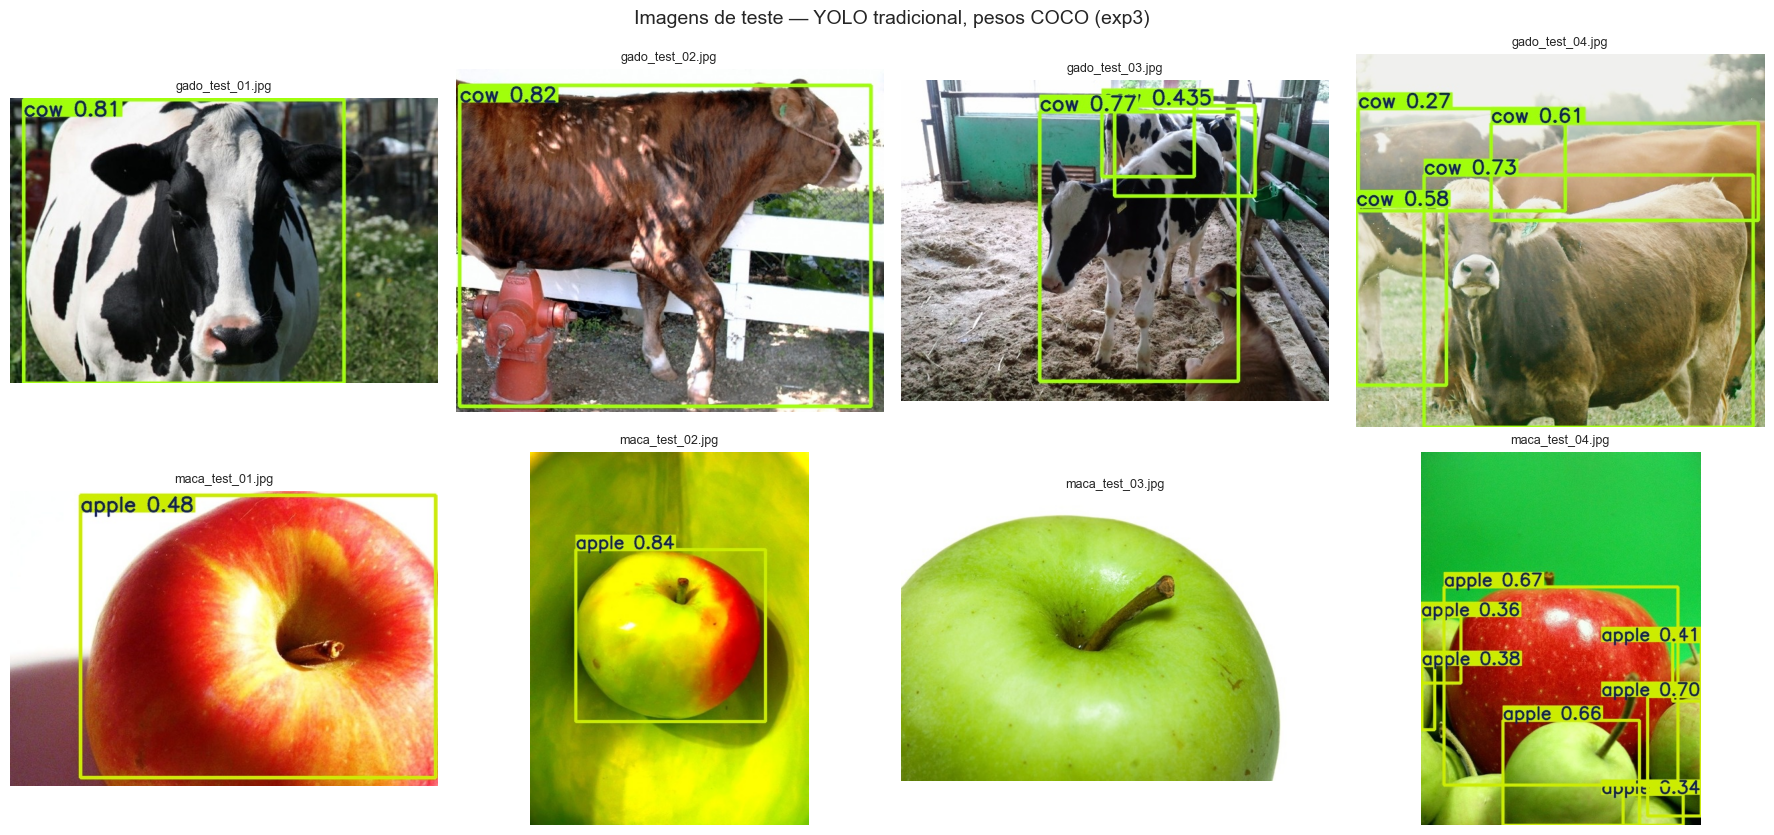

In [14]:
COCO_PARA_NOSSO = {19: 0, 47: 1}                            # cow → gado, apple → maca

antes = set((YOLO_DIR / 'runs' / 'detect').glob('exp*'))
rodar([sys.executable, 'detect.py', '--weights', 'yolov5s.pt', '--source', str(DATASET / 'images' / 'test'),
       '--img', str(IMG), '--conf-thres', '0.25', '--classes', '19', '47', '--device', DISPOSITIVO], linhas_finais=3)
pasta_coco = sorted(set((YOLO_DIR / 'runs' / 'detect').glob('exp*')) - antes, key=lambda p: p.stat().st_mtime)[-1]
galeria(pasta_coco, f'Imagens de teste — YOLO tradicional, pesos COCO ({pasta_coco.name})')

### 7.1 Avaliação padronizada dos detectores

Para comparar A e B com a mesma régua, carregamos cada modelo pelo
`torch.hub`, rodamos as 8 imagens de teste e calculamos as métricas com uma
função própria (IoU ≥ 0,5, AP com interpolação em todos os pontos, como no VOC).
Medimos também o **tempo de inferência por imagem**, depois de um aquecimento.

In [15]:
IMAGENS_TESTE = sorted((DATASET / 'images' / 'test').glob('*.jpg'))
CLASSE_REAL = {p.name: 0 if p.name.startswith('gado') else 1 for p in IMAGENS_TESTE}

def caixas_reais(img_path):
    """Caixas do Make Sense em pixels: [classe, x1, y1, x2, y2]."""
    w, h = Image.open(img_path).size
    out = []
    for cls, xc, yc, bw, bh in ler_rotulos(DATASET / 'labels' / 'test' / img_path.with_suffix('.txt').name):
        out.append([int(cls), (xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h])
    return out

def iou(a, b):
    """Interseção sobre união entre duas caixas [x1, y1, x2, y2]."""
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

def ap_voc(recall, precisao):
    """Área sob a curva precisão-recall com interpolação em todos os pontos."""
    r = np.concatenate(([0.], recall, [1.])); p = np.concatenate(([1.], precisao, [0.]))
    p = np.flip(np.maximum.accumulate(np.flip(p)))          # envelope monotônico da precisão
    i = np.where(r[1:] != r[:-1])[0]
    return float(np.sum((r[i + 1] - r[i]) * p[i + 1]))

def avaliar_detector(nome, pesos, mapa_classes=None, conf=0.25):
    """Roda um detector no teste e devolve métricas de detecção e de classificação da imagem."""
    modelo = torch.hub.load(str(YOLO_DIR), 'custom', path=str(pesos), source='local', verbose=False)
    modelo.conf = 0.001                                      # guarda tudo para calcular o AP; o limiar entra depois
    if mapa_classes:
        modelo.classes = list(mapa_classes)                 # só as classes de interesse (COCO)
    modelo(str(IMAGENS_TESTE[0]), size=IMG)                  # aquecimento (não entra na medição de tempo)

    deteccoes, tempos = [], []
    for p in IMAGENS_TESTE:
        if GPU: torch.cuda.synchronize()
        t0 = time.perf_counter()
        pred = modelo(str(p), size=IMG).xyxy[0].cpu().numpy()  # [x1, y1, x2, y2, conf, classe]
        if GPU: torch.cuda.synchronize()
        tempos.append((time.perf_counter() - t0) * 1000)
        for x1, y1, x2, y2, cf, cl in pred:
            cl = mapa_classes[int(cl)] if mapa_classes else int(cl)
            deteccoes.append((p.name, cl, float(cf), [x1, y1, x2, y2]))

    # --- detecção: AP por classe com IoU >= 0,5
    aps, tp_total, fp_total, n_reais = [], 0, 0, 0
    for cls in (0, 1):
        reais = {p.name: [c[1:] for c in caixas_reais(p) if c[0] == cls] for p in IMAGENS_TESTE}
        usados = {k: [False] * len(v) for k, v in reais.items()}
        n_cls = sum(len(v) for v in reais.values()); n_reais += n_cls
        dets = sorted([d for d in deteccoes if d[1] == cls], key=lambda d: -d[2])
        tp = []
        for img, _, cf, caixa in dets:
            ious = [iou(caixa, g) for g in reais[img]]
            j = int(np.argmax(ious)) if ious else -1
            acerto = j >= 0 and ious[j] >= 0.5 and not usados[img][j]
            if acerto: usados[img][j] = True
            tp.append(acerto)
            if cf >= conf: tp_total += acerto; fp_total += (not acerto)
        tp = np.array(tp, dtype=float)
        acum_tp, acum_fp = np.cumsum(tp), np.cumsum(1 - tp)
        aps.append(ap_voc(acum_tp / max(n_cls, 1), acum_tp / np.maximum(acum_tp + acum_fp, 1e-9)) if len(tp) else 0.0)

    # --- classificação da imagem: classe da detecção mais confiante (acima do limiar)
    acertos = 0
    for p in IMAGENS_TESTE:
        dets = [d for d in deteccoes if d[0] == p.name and d[2] >= conf]
        prevista = max(dets, key=lambda d: d[2])[1] if dets else -1   # -1 = nada detectado
        acertos += prevista == CLASSE_REAL[p.name]

    return {'abordagem': nome, 'mAP@0.5 (teste)': float(np.mean(aps)), 'AP gado': aps[0], 'AP maçã': aps[1],
            'precisão@0.25': tp_total / max(tp_total + fp_total, 1), 'recall@0.25': tp_total / n_reais,
            'acurácia (imagem)': acertos / len(IMAGENS_TESTE), 'inferência (ms/img)': float(np.median(tempos))}

aval_detectores = pd.DataFrame(
    [avaliar_detector(f'A · YOLOv5 customizado ({nome})', PESOS[nome]) for nome in EXPERIMENTOS] +
    [avaliar_detector('B · YOLO tradicional (COCO)', YOLO_DIR / 'yolov5s.pt', COCO_PARA_NOSSO)])
display(aval_detectores.round(3))

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


,abordagem,mAP@0.5 (teste),AP gado,AP maçã,precisão@0.25,recall@0.25,acurácia (imagem),inferência (ms/img)
0,A · YOLOv5 customizado (30 épocas),0.748,0.804,0.693,0.778,0.583,0.875,30.714
1,A · YOLOv5 customizado (60 épocas),0.798,0.746,0.850,0.700,0.583,0.875,21.351
2,B · YOLO tradicional (COCO),0.665,0.673,0.658,0.444,0.667,0.875,20.609


**O que esperar e o que observar.** O YOLO tradicional já "conhece" vaca e maçã,
então a pergunta não é se ele funciona, e sim **quanto o ajuste fino acrescenta**.
Duas diferenças pesam: o COCO rotula *cow* como um animal visto de forma ampla,
enquanto nossa base tem enquadramentos fechados (só a cabeça, o animal deitado);
e o COCO tem muitas maçãs pequenas em fruteiras, enquanto as nossas ocupam boa parte
da foto.

## 8. CNN treinada do zero

Uma rede convolucional pequena, sem nenhum peso pré-treinado, que recebe a
imagem inteira e responde **gado** ou **maçã**. Ela usa exatamente as mesmas
divisões de treino, validação e teste.

Arquitetura (capítulo 9): três blocos **convolução + ReLU + max pooling** extraem
características; *Global Average Pooling* e *Dropout* reduzem parâmetros e
overfitting; uma saída **sigmoide** dá a probabilidade de "maçã". Com só 64
imagens de treino, usamos **aumento de dados** (espelhamento, rotação, zoom e
contraste), *early stopping* na perda de validação e redução da taxa de
aprendizado quando a perda estabiliza.

**Como escolhemos a configuração — sem olhar o teste.** A primeira versão (160 px,
com *Batch Normalization* e paciência 15) ficava presa em ~50% de acerto: com
lotes de 16 imagens e só 64 exemplos, as estatísticas da normalização oscilam e o
*early stopping* devolvia os pesos das primeiras épocas. Comparamos variações
**usando apenas treino e validação**, com duas sementes aleatórias:

| Configuração | Validação (semente 42) | Validação (semente 7) |
|---|---|---|
| 160 px, BatchNorm, paciência 15 | 62% — não aprendeu | 50% — não aprendeu |
| 128 px, BatchNorm, paciência 40 | 100% | 50% — não aprendeu |
| **128 px, sem BatchNorm, paciência 40** | **100%** | **100%** |

Ficamos com a única configuração estável nas duas sementes. O teste só é usado
depois, uma vez, para medir o resultado.

In [16]:
import tensorflow as tf                                     # Keras (TensorFlow) para a CNN
from tensorflow import keras
from tensorflow.keras import layers

SEMENTE = 42
random.seed(SEMENTE); np.random.seed(SEMENTE); tf.random.set_seed(SEMENTE)   # reprodutibilidade
LADO = 128                                                  # imagens redimensionadas para 128x128

def carregar(etapa):
    """Lê as imagens de uma etapa e devolve (X, y), com y = 0 para gado e 1 para maçã."""
    caminhos = sorted((DATASET / 'images' / etapa).glob('*.jpg'))
    X = np.stack([np.asarray(Image.open(p).convert('RGB').resize((LADO, LADO))) for p in caminhos]).astype('float32')
    y = np.array([0 if p.name.startswith('gado') else 1 for p in caminhos])
    return X, y, [p.name for p in caminhos]

X_tr, y_tr, _ = carregar('train'); X_va, y_va, _ = carregar('val'); X_te, y_te, nomes_te = carregar('test')
print('treino', X_tr.shape, '| validação', X_va.shape, '| teste', X_te.shape)

aumento = keras.Sequential([layers.RandomFlip('horizontal'), layers.RandomRotation(0.08),
                            layers.RandomZoom(0.15), layers.RandomContrast(0.2)], name='aumento')

def bloco(x, filtros):
    """Convolução 3x3 + ReLU + max pooling 2x2 (sem BatchNorm: instável com só 64 imagens)."""
    x = layers.Conv2D(filtros, 3, padding='same', activation='relu')(x)
    return layers.MaxPooling2D()(x)

entrada = keras.Input((LADO, LADO, 3))
x = aumento(entrada)                                        # só atua no treino
x = layers.Rescaling(1 / 255)(x)                            # pixels 0-255 → 0-1
for filtros in (32, 64, 128):
    x = bloco(x, filtros)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
saida = layers.Dense(1, activation='sigmoid')(x)            # probabilidade de ser maçã
cnn = keras.Model(entrada, saida, name='cnn_do_zero')
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

treino (64, 128, 128, 3) | validação (8, 128, 128, 3) | teste (8, 128, 128, 3)


Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

Treino: 137 épocas em 31.7 s (melhor época pela validação: 97)


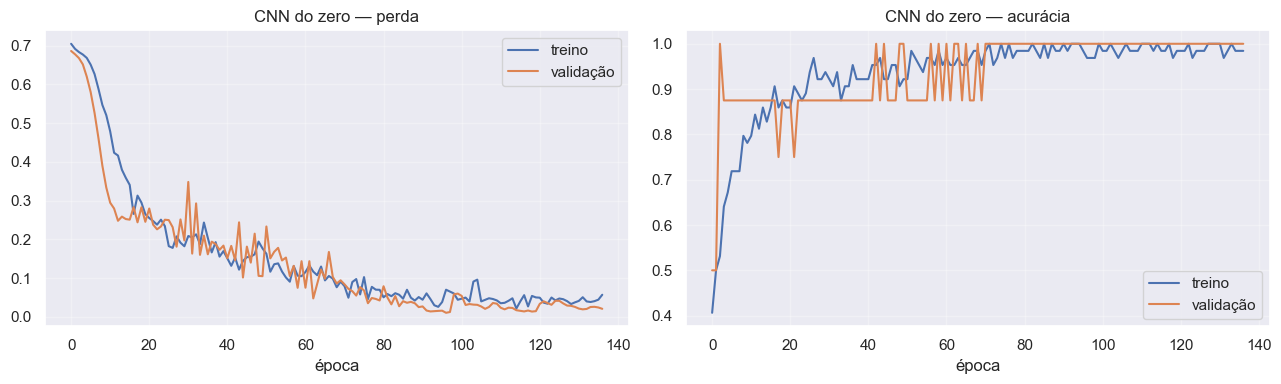

In [17]:
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True),  # para quando a validação não melhora
             keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=10, min_lr=1e-5)]   # passos menores no platô
t0 = time.time()
hist_cnn = cnn.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=150, batch_size=16,
                   callbacks=callbacks, verbose=0)
tempo_cnn = time.time() - t0
print(f'Treino: {len(hist_cnn.history["loss"])} épocas em {tempo_cnn:.1f} s '
      f'(melhor época pela validação: {int(np.argmin(hist_cnn.history["val_loss"])) + 1})')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for chave, rot in (('loss', 'treino'), ('val_loss', 'validação')):
    a1.plot(hist_cnn.history[chave], label=rot)
for chave, rot in (('accuracy', 'treino'), ('val_accuracy', 'validação')):
    a2.plot(hist_cnn.history[chave], label=rot)
a1.set_title('CNN do zero — perda'); a2.set_title('CNN do zero — acurácia')
for ax in (a1, a2): ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTADOS / 'cnn_curvas.png', dpi=120); mostrar(fig)

In [18]:
prever = lambda X: cnn(X, training=False).numpy().ravel()  # chamada direta: sem o overhead do predict() por lote
prever(X_te[:1])                                            # aquecimento
tempos_cnn = []
for i in range(len(X_te)):                                  # uma imagem por vez, como numa câmera
    t0 = time.perf_counter(); prever(X_te[i:i + 1]); tempos_cnn.append((time.perf_counter() - t0) * 1000)
prob = prever(X_te)                                         # probabilidade de ser maçã
pred = (prob >= 0.5).astype(int)

acuracia_cnn = float((pred == y_te).mean())
acuracia_cnn_val = float(((prever(X_va) >= 0.5).astype(int) == y_va).mean())
print(f'Acurácia — validação: {acuracia_cnn_val:.0%} | teste: {acuracia_cnn:.0%}')
display(pd.DataFrame({'imagem': nomes_te, 'real': [NOMES[v] for v in y_te],
                      'prevista': [NOMES[v] for v in pred], 'P(maçã)': prob.round(3)}))

Acurácia — validação: 100% | teste: 100%


,imagem,real,prevista,P(maçã)
0,gado_test_01.jpg,gado,gado,0.000
1,gado_test_02.jpg,gado,gado,0.000
2,gado_test_03.jpg,gado,gado,0.000
3,gado_test_04.jpg,gado,gado,0.004
4,maca_test_01.jpg,maca,maca,1.000
5,maca_test_02.jpg,maca,maca,1.000
6,maca_test_03.jpg,maca,maca,1.000
7,maca_test_04.jpg,maca,maca,1.000


## 9. Comparação final das três abordagens

Os quatro critérios pedidos no enunciado: **facilidade de uso/integração**,
**precisão**, **tempo de treinamento/customização** e **tempo de inferência**.

,mAP@0.5 (teste),acurácia (imagem),inferência (ms/img),tempo de treino (s),localiza o objeto?,precisa treinar?
abordagem,,,,,,
A · YOLOv5 customizado (30 épocas),0.748,0.875,30.714,155.359,sim,sim (ajuste fino)
A · YOLOv5 customizado (60 épocas),0.798,0.875,21.351,129.934,sim,sim (ajuste fino)
B · YOLO tradicional (COCO),0.665,0.875,20.609,0.000,sim,não
C · CNN do zero (classificação),NaN,1.000,12.539,31.670,não,sim (do zero)


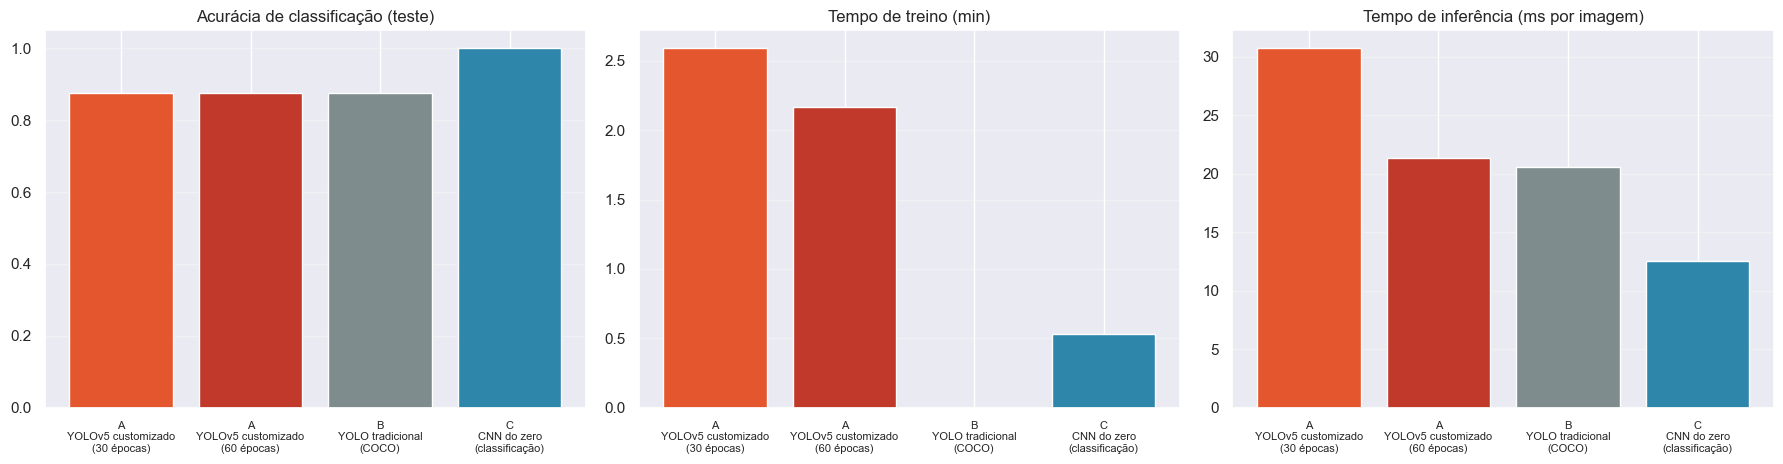

In [19]:
treino_yolo = {f'A · YOLOv5 customizado ({n})': tempos_treino[n] for n in EXPERIMENTOS}
final = aval_detectores.set_index('abordagem')[['mAP@0.5 (teste)', 'acurácia (imagem)', 'inferência (ms/img)']].copy()
final['tempo de treino (s)'] = [treino_yolo.get(a, 0.0) for a in final.index]
final.loc['C · CNN do zero (classificação)'] = [np.nan, acuracia_cnn, float(np.median(tempos_cnn)), tempo_cnn]
final['localiza o objeto?'] = ['sim', 'sim', 'sim', 'não']
final['precisa treinar?'] = ['sim (ajuste fino)', 'sim (ajuste fino)', 'não', 'sim (do zero)']
display(final.round(3))
final.to_csv(RESULTADOS / 'comparacao_final.csv')

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(18, 4.8))
rotulos = [i.split(' · ')[0] + '\n' + i.split(' · ')[1].replace(' (', '\n(') for i in final.index]
cores = ['#e4572e', '#c0392b', '#7f8c8d', '#2e86ab']
a1.bar(rotulos, final['acurácia (imagem)'], color=cores); a1.set_ylim(0, 1.05); a1.set_title('Acurácia de classificação (teste)')
a2.bar(rotulos, final['tempo de treino (s)'] / 60, color=cores); a2.set_title('Tempo de treino (min)')
a3.bar(rotulos, final['inferência (ms/img)'], color=cores); a3.set_title('Tempo de inferência (ms por imagem)')
for ax in (a1, a2, a3): ax.tick_params(axis='x', labelsize=8); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(RESULTADOS / 'comparacao_final.png', dpi=120); mostrar(fig)

### Avaliação crítica


| Critério | A · YOLOv5 customizado | B · YOLO tradicional (COCO) | C · CNN do zero |
|---|---|---|---|
| **Facilidade de uso / integração** | média: exige rotular caixas (Make Sense) e treinar; depois, um `best.pt` que roda com o mesmo `detect.py` | **a mais fácil**: zero treino, `yolov5s.pt` pronto; mas só reconhece as 80 classes do COCO | média: rótulo só por pasta (sem caixas), mas arquitetura e treino são escritos à mão |
| **Precisão (teste)** | **mAP@0.5 = 0,798** (60 ép.) — a melhor detecção; acurácia por imagem 87,5% | mAP@0.5 = 0,665 — 13 pontos abaixo; acurácia 87,5% | **acurácia 100%**, mas só diz *o que* há na foto, não *onde* |
| **Tempo de treino / customização** | ~2 min de GPU, depois de desenhar 101 caixas nas 80 fotos | nenhum | **~30 s** de GPU, rótulo trivial |
| **Tempo de inferência** | ~21 ms/imagem (com leitura e pré-processamento) | ~21 ms/imagem — mesma arquitetura | **~13 ms/imagem** — ~75 vezes menos parâmetros (93 mil × 7 milhões) |

**O que os números dizem.**

- **O ajuste fino vale a pena.** O mesmo YOLOv5s, com os mesmos pesos de partida,
  passou de 0,665 para 0,798 de mAP@0.5 só com 64 fotos rotuladas. O ganho vem da
  **maçã** (AP 0,658 → 0,850): o COCO aprendeu maçãs pequenas em fruteiras e
  **não reconheceu a maçã verde em close** de `maca_test_03`, que o modelo
  customizado acerta.
- **Mas o COCO é melhor em rebanho.** Na foto `gado_test_04`, a YOLO tradicional
  separa cada animal; a nossa não detecta nenhum. Ela viu milhares de cenas com
  várias vacas — nós, poucas. É a evidência mais clara de que **o que limita o
  modelo customizado é a base, não a técnica**.
- **A CNN acertou 100% porque o problema dela é mais fácil.** Classificar a
  imagem inteira entre "gado" e "maçã" — cor, textura e fundo já separam bem as
  duas classes — é muito mais simples que localizar cada objeto com IoU ≥ 0,5. Com
  só 8 imagens de teste, 100% significa "acertou as 8", não "nunca erra". E ela
  **não conta** objetos nem diz onde estão — não serve para contar rebanho nem
  para guiar uma câmera.
- **Tempo de inferência não é gargalo em nenhuma delas.** Todas ficam bem abaixo
  dos ~33 ms de um quadro a 30 fps — nas três, daria para processar vídeo ao vivo.

> **Observação sobre a régua.** Os mAP desta seção vêm da avaliação própria da
> seção 7.1, aplicada igualmente a A e B. Eles diferem um pouco dos da seção 4
> (`val.py` do YOLOv5) porque a interpolação da curva precisão-recall e o
> pré-processamento são diferentes; o que importa é que **A e B foram medidos com
> a mesma régua**.

**Recomendação para a FarmTech.** Para *reconhecer e localizar* gado e maçã — o
pedido do cliente —, o **YOLOv5 customizado com 60 épocas** é a escolha: melhor
mAP, mesmo custo de inferência do modelo pronto e integração direta com a câmera
(ESP32-CAM → servidor com `best.pt`, como no capítulo 3). A YOLO tradicional é um
bom *ponto de partida* para classes que já existem no COCO, e a CNN do zero é
útil quando basta saber *o que* aparece na foto, como triagem rápida e barata.

## 10. Resultados salvos no Google Drive

Pesos treinados, curvas, tabelas e as imagens processadas ficam em
`MyDrive/FarmTech_Fase6/resultados/`, para consulta sem precisar re-executar.

In [20]:
for nome, pesos in PESOS.items():                           # pesos best.pt de cada simulação
    shutil.copy(pesos, RESULTADOS / f"best_{nome.split()[0]}ep.pt")
for pasta in list(pastas_detect.values()) + [pasta_coco]:   # imagens de teste processadas (runs/detect/expX)
    shutil.copytree(pasta, RESULTADOS / 'detect' / pasta.name, dirs_exist_ok=True)
for nome in EXPERIMENTOS:                                   # curvas e métricas completas de cada treino
    shutil.copytree(PESOS[nome].parents[1], RESULTADOS / 'train' / PESOS[nome].parents[1].name,
                    dirs_exist_ok=True, ignore=shutil.ignore_patterns('*.pt'))
cnn.save(RESULTADOS / 'cnn_do_zero.keras')
print('\n'.join(sorted(str(p.relative_to(PROJETO)) for p in RESULTADOS.rglob('*') if p.is_file())[:40]))

resultados/best_30ep.pt
resultados/best_60ep.pt
resultados/cnn_curvas.png
resultados/cnn_do_zero.keras
resultados/comparacao_30x60.csv
resultados/comparacao_final.csv
resultados/comparacao_final.png
resultados/curvas_treino.png
resultados/detect/exp/gado_test_01.jpg
resultados/detect/exp/gado_test_02.jpg
resultados/detect/exp/gado_test_03.jpg
resultados/detect/exp/gado_test_04.jpg
resultados/detect/exp/maca_test_01.jpg
resultados/detect/exp/maca_test_02.jpg
resultados/detect/exp/maca_test_03.jpg
resultados/detect/exp/maca_test_04.jpg
resultados/detect/exp2/gado_test_01.jpg
resultados/detect/exp2/gado_test_02.jpg
resultados/detect/exp2/gado_test_03.jpg
resultados/detect/exp2/gado_test_04.jpg
resultados/detect/exp2/maca_test_01.jpg
resultados/detect/exp2/maca_test_02.jpg
resultados/detect/exp2/maca_test_03.jpg
resultados/detect/exp2/maca_test_04.jpg
resultados/detect/exp3/gado_test_01.jpg
resultados/detect/exp3/gado_test_02.jpg
resultados/detect/exp3/gado_test_03.jpg
resultados/detect/ex

## 11. Pontos fortes, limitações e próximos passos

**Pontos fortes**

- **Pipeline completo e reprodutível:** base curada e documentada (autoria e
  licença de cada foto), rótulos do Make Sense versionados, YOLOv5 fixado num
  commit, semente fixa, e um notebook que monta o próprio Drive e baixa a base —
  roda no Colab de qualquer pessoa sem configuração.
- **Comparação justa:** as duas simulações diferem só nas épocas; os três
  modelos da Entrega 2 usam as mesmas imagens de teste e a mesma régua.
- **Avaliação honesta:** o teste nunca participou de nenhuma escolha; a
  configuração da CNN foi decidida só com a validação; os erros estão mostrados
  imagem por imagem, não escondidos na média.
- **Resultado útil:** com 64 fotos de treino, o detector supera o modelo pronto
  em 13 pontos de mAP@0.5 e já funciona em tempo real.

**Limitações**

- **Base pequena.** 8 imagens de validação e 8 de teste tornam as métricas
  instáveis: um objeto muda o mAP em vários pontos, e execuções idênticas variam
  (seção 5, item 5).
- **Poucas cenas de rebanho.** A base tem em média 1,3 objeto por imagem; o
  modelo falha justamente nas fotos com 3 animais.
- **Rotulagem incompleta em um caso.** Em `maca_test_04`, só a maçã central foi
  rotulada; as maçãs cortadas na borda contam como falsos positivos e derrubam a
  precisão da classe.
- **Fotos "de internet".** O Open Images traz fotos variadas, mas não reproduz as
  condições do cliente (câmera fixa, ângulo de cima, noite, chuva). O desempenho
  no campo precisa ser medido com imagens do próprio cliente.
- **A CNN só classifica:** não localiza nem conta objetos.

**Próximos passos**

1. Ampliar a base com fotos de rebanho e com imagens da câmera do próprio cliente,
   e rotular todas as maçãs visíveis.
2. Validação cruzada ou base de teste maior, para métricas com menos variância.
3. Testar o YOLOv5m (maior) e mais épocas, já que a curva de validação ainda subia
   aos 60.
4. Integrar com o ESP32-CAM: a câmera envia os quadros por Wi-Fi a um servidor
   que roda o `best.pt` (o "Ir Além" da fase).

---
**Referências**

- FIAP — Fase 6, capítulos 3 (ESP32 e visão computacional), 9 (CNN) e 10 (detecção e segmentação).
- Ultralytics. *YOLOv5*. <https://github.com/ultralytics/yolov5>
- Kuznetsova, A. et al. *The Open Images Dataset V4*. IJCV, 2020. Imagens CC BY 2.0 — autoria em `dataset/fontes.csv`.
- Skalski, P. *Make Sense*. <https://www.makesense.ai>
- Lin, T.-Y. et al. *Microsoft COCO: Common Objects in Context*. ECCV, 2014.